# Signatures Analysis

## Load in libraries, functions, and datasets 

In [1]:
import pickle
import statistics
import matplotlib.pyplot as plt
import re
import pandas as pd
import numpy as np
from collections import Counter
from datetime import datetime
from dateutil.relativedelta import relativedelta
import powerlaw
import scipy as sp
import os
import sys
import time
import random

In [24]:
# Australia
aus_pets_path = '../data/aus/clean/aus_deidentified_min_fields.pkl'

# UK
uk_pets_path = '../data/uk/clean/uk_deidentified_min_fields.pkl'

# Canada
can_pets_path = '../data/canada/clean/can_deidentified_min_fields.pkl'

# Germany
ger_pets_path = '../data/germany/clean/ger_sigs.pkl'

In [25]:
with open(aus_pets_path, 'rb') as f:
    aus = pickle.load(f, encoding="utf-8")
    
with open(can_pets_path, 'rb') as f:
    can = pickle.load(f, encoding="utf-8")
    
with open(uk_pets_path, 'rb') as f:
    uk = pickle.load(f, encoding="utf-8")
    
with open(ger_pets_path, 'rb') as f:
    ger = pickle.load(f, encoding="utf-8")

In [26]:
print(len(aus))
print(len(can))
print(len(uk))
print(len(ger))

# print(aus[list(aus.keys())[0]]['date'])
# print(aus[list(aus.keys())[-1]]['date'])

# print(can[list(can.keys())[0]]['date'])
# print(can[list(can.keys())[-1]]['date'])

# print(uk[list(uk.keys())[0]]['date'])
# print(uk[list(uk.keys())[-1]]['date'])

# print(ger[list(ger.keys())[0]]['date'])
# print(ger[list(ger.keys())[-3]]['date'])

3906
2034
52154
6650


In [5]:
# sorting signatures in ascending order
aus_sig = [aus[k]['signatures'] for k in aus.keys()]
aus_sig.sort()
can_sig = [can[k]['signatures'] for k in can.keys()]
can_sig.sort()
uk_sig = [uk[k]['signatures'] for k in uk.keys()]
uk_sig.sort()
ger_sig = [ger[k]['signatures'] for k in ger.keys()]
ger_sig.sort()

In [6]:
# downsample UK data for goodness-of-fit test
n = round(len(uk_sig)*0.2)
print(n)

random.seed(1000)
uk_sig_downsample = random.sample(uk_sig, n)

print(min(uk_sig_downsample))
print(max(uk_sig_downsample))

10431
1
4150262


## Summary stats

In [7]:
def sig_stats(sig, threshold):
    print(f'Min: {min(sig)}')
    print(f'Mean: {round(np.mean(sig))}')
    print(f'Median: {np.median(sig)}') # median using the traditional taking the middle of the two even points
    print(f'Max: {max(sig)}')
    print(f'Mode: {statistics.multimode(sig)}')
    print(f"Percentage <= 10: {round((sum([x <= 10 for x in sig])/len(sig)*100),2)}")
    print(f"Percentage <= 100: {round((sum([x <= 100 for x in sig])/len(sig)*100),2)}")
    print(f"Percentage >= threshold: {round((sum([x >= threshold for x in sig])/len(sig)*100),2)}")

In [8]:
sig_stats(aus_sig, 50)

Min: 1
Mean: 1760
Median: 29.0
Max: 501128
Mode: [2]
Percentage <= 10: 29.37
Percentage <= 100: 68.33
Percentage >= threshold: 41.32


In [9]:
sig_stats(can_sig, 500)

Min: 12
Mean: 3753
Median: 774.0
Max: 387487
Mode: [557]
Percentage <= 10: 0.0
Percentage <= 100: 9.59
Percentage >= threshold: 72.27


In [10]:
sig_stats(uk_sig, 10000)

Min: 1
Mean: 2819
Median: 43.0
Max: 6103056
Mode: [2]
Percentage <= 10: 25.33
Percentage <= 100: 63.53
Percentage >= threshold: 4.43


In [11]:
sig_stats(ger_sig, 30000)

Min: 0
Mean: 1437
Median: 84.0
Max: 413473
Mode: [49]
Percentage <= 10: 0.5
Percentage <= 100: 57.85
Percentage >= threshold: 1.31


## Figure 2

In [12]:
def graph_ed3(x, xmax_flag):    
    x=sorted(x,reverse=True)
    r=np.arange(1*len(x))+1
    P = sum(x) # total sigs
    N = len(x) # number of petitions
    
    rng = np.random.default_rng(seed=2)
    xgaussian = rng.normal(np.mean(x), np.std(x), N)
    #xgaussian = sorted(xgaussian,reverse=True)
    
    C=P/np.sum((1/r)[:N])
    return (x, r, C, xgaussian)
    

def four_plots(sig_list, cflag_list, threshold_list, xmax_flag, out_file = None):
    fig, ax = plt.subplots(2, 2, figsize=(10, 10))
    ax_list = [(0,0), (0,1), (1,0), (1,1)]
    
    for i in range(len(ax_list)):
        x, r, C, xgaussian = graph_ed3(sig_list[i], xmax_flag)
        
        print(cflag_list[i])
        
        c_flag = cflag_list[i]
        thresholds = threshold_list[i]
        threshold_strings = threshold_string[i]
        
        ax[ax_list[i]].set_yscale("log")
        ax[ax_list[i]].set_xscale("log")
        ax[ax_list[i]].set_xlabel(r"$Rank,~r$",fontsize=14)
        ax[ax_list[i]].set_ylabel(r"$Signatures,~s_{r}$",fontsize=14)
        
        ax[ax_list[i]].plot(range(len(x)+1)[1:],x,"o-",color="tomato",markeredgecolor="tomato",label="Data")

        ax[ax_list[i]].plot(r,C/r,"-",color="black",label="Zipf's law")
        
        ax[ax_list[i]].plot(range(len(x)+1)[1:],sorted(xgaussian,reverse=True),color="green",label="Gaussian") #":",

        threshold_cols = ['cornflowerblue', 'royalblue']
        for t in range(len(thresholds)):
            # ax[ax_list[i]].hlines(thresholds[t], xmin = range(len(x)+1)[0], xmax = range(len(x)+1)[-1], linestyle = "--", label = f'Threshold: {threshold_strings[t]}')
            ax[ax_list[i]].hlines(thresholds[t], xmin = r[0], xmax = r[-1], linestyle = ":", color = threshold_cols[t], label = f'Threshold: {threshold_strings[t]}') #--
        
        
        handles, labels = ax[ax_list[i]].get_legend_handles_labels()
        filtered_handles = handles[3:]
        filtered_labels = labels[3:]
        legend1 = ax[ax_list[i]].legend(filtered_handles, filtered_labels, fontsize=12,loc=1)
        ax[ax_list[i]].add_artist(legend1)

        if i == 0:
            filtered_handles = handles[:3]
            filtered_labels = labels[:3]
            ax[ax_list[i]].legend(filtered_handles, filtered_labels, fontsize=13,loc=3)

        ax[ax_list[i]].tick_params(axis='both', which='major', labelsize=13)
        ax[ax_list[i]].set_title(c_flag, fontsize = 16)
    plt.tight_layout()
    
    if out_file != None:
        pass
        #plt.savefig(out_file, dpi = 300, bbox_inches='tight')
    else:
        plt.show()

Australia
Canada
UK
Germany


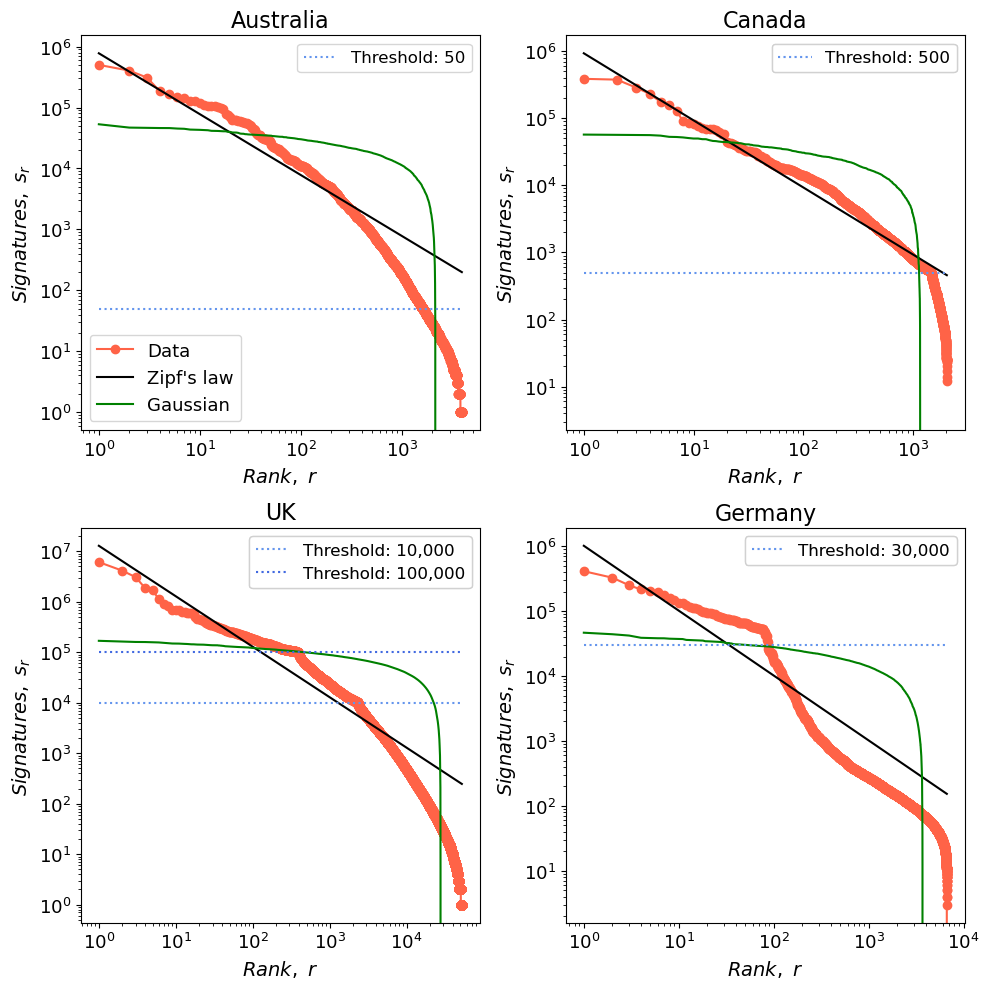

In [13]:
threshold_list = [[50], [500],[10000, 100000], [30000]]
threshold_string = [['50'], ['500'],['10,000', '100,000'], ['30,000']]
four_plots([aus_sig, can_sig, uk_sig, ger_sig], 
           ['Australia', 'Canada', 'UK', 'Germany'], 
           threshold_list, False, 
           out_file = '../figures/four-country-sig-dist-zipfs.png')


## Power law goodness-of-fit test - Clauset et al. (2009)

In [27]:
def fit_features(sig, cflag):
    fit = powerlaw.Fit(sig, discrete = True, verbose = False)
    x_min = fit.xmin
    alpha = fit.alpha
    D = fit.D

    print(cflag)
    print(f"xmin: {x_min}")
    print(f"alpha: {round(alpha, 3)}")
    print(f"D: {round(D, 3)}")
    print(f"N: {len(sig)}")
    print(f"N_tail (s >= x_min): {len([x for x in sig if x >= x_min])}")
    print()
    
fit_features(aus_sig, 'Aus')
fit_features(can_sig, 'Can')
fit_features(ger_sig, 'Ger')
fit_features(uk_sig_downsample, 'UK')

Aus
xmin: 13.0
alpha: 1.407
D: 0.048
N: 3906
N_tail (s >= x_min): 2624

Can
xmin: 502.0
alpha: 1.798
D: 0.028
N: 2034
N_tail (s >= x_min): 1470

Ger
xmin: 51.0
alpha: 1.834
D: 0.045
N: 6650
N_tail (s >= x_min): 4796

UK
xmin: 41.0
alpha: 1.443
D: 0.042
N: 10431
N_tail (s >= x_min): 5311



In [65]:
# From copilot 23/02/2026 - modified to fit with above code

def bootstrap_KS_pvalue(sig, fit, xmin, D, N, seed_in):
    """
    Compute the Clauset-Shalizi-Newman bootstrap p-value for a power-law fit.
    """
    # Split data into above or below the x_min of the powerlaw fitted to the observed data
    sigs_bottom = [x for x in sig if x < xmin ] # non-tail observations
    n = len(sig)
    n_other = len(sigs_bottom)
    n_tail = n - n_other # data points >= the xmin value 
    
    flag_list = [1]*n_tail + [0]*n_other # has the probabilities of the two outcomes we are looking for
    
    # 2. Bootstrap loop
    Ds = []
    
    if seed_in == None:
        rng = random.Random(12345) # fixes seed for samplings
        np.random.seed(42) # fixes seed for fit.generate_random()
    else:
        rng = random.Random(seed_in) # fixes seed for samplings
        np.random.seed(seed_in + 2) # fixes seed for fit.generate_random()
        
    
    for i in range(N):
        # sample from flag_list n times
        flags = rng.choices(flag_list, k=n) 
        n_synth_samp = sum(flags) # sum of the 1s
        n_true_samp = n - n_synth_samp # number of 0s sampled

        # 2a. Generate synthetic data from the fitted model
        synthetic = list(fit.generate_random(n_synth_samp))

        if n_other > 0: # in case xmin = min(sig) and sig_bottom has 0 values
            synthetic.extend(rng.choices(sigs_bottom, k = n_true_samp))
                
        # 2b. Re-fit synthetic data
        fit_syn = powerlaw.Fit(synthetic, discrete=True, verbose = False)

        # 2c. Compute KS statistic for synthetic dataset
        Ds.append(fit_syn.D)
        
        if i%100 == 0:
            print(i)

    # 3. p-value = fraction of synthetic KS >= empirical KS
    p_value = len([x for x in Ds if x >= D])/len(Ds)

    return Ds, p_value

def goodness_of_fit_pipeline(sig, N = 2500, seed_in = None):
    fit = powerlaw.Fit(sig, discrete = True, verbose = False)
    
    x_min = fit.xmin
    alpha = fit.alpha
    D = fit.D
    
    print(f"xmin: {x_min}")
    print(f"alpha: {alpha}")
    print(f"D: {D}")
    
    # Create new fit based on parameters    
    fit_theoretic = powerlaw.Power_Law(xmin=x_min, parameters=[alpha], discrete = True) # needs to be discrete as well
    
    start_time = time.perf_counter()
    Ds, p_value = bootstrap_KS_pvalue(sig, fit_theoretic, x_min, D, N, seed_in)
    end_time = time.perf_counter()
    execution_time = end_time - start_time
    print(f"Execution time: {execution_time:.6f} seconds")
    
    return x_min, alpha, D, Ds, p_value

In [ ]:
goodness_of_fits = {'country': [], 'Ds': [], 'p-val': []}

In [17]:
Ds, p_value = goodness_of_fit_pipeline(aus_sig, 2500, None)
goodness_of_fits['country'].append('Australia')
goodness_of_fits['Ds'].append(Ds)
goodness_of_fits['p-val'].append(p_value)

0


/Users/shankari/anaconda3/lib/python3.11/site-packages/powerlaw/distributions.py:2053: RuntimeWarning: divide by zero encountered in scalar divide
  C = 1.0/C
/Users/shankari/anaconda3/lib/python3.11/site-packages/scipy/optimize/_optimize.py:869: RuntimeWarning: invalid value encountered in subtract
  np.max(np.abs(fsim[0] - fsim[1:])) <= fatol):
/Users/shankari/anaconda3/lib/python3.11/site-packages/powerlaw/distributions.py:2053: RuntimeWarning: divide by zero encountered in scalar divide
  C = 1.0/C
/Users/shankari/anaconda3/lib/python3.11/site-packages/scipy/optimize/_optimize.py:869: RuntimeWarning: invalid value encountered in subtract
  np.max(np.abs(fsim[0] - fsim[1:])) <= fatol):
/Users/shankari/anaconda3/lib/python3.11/site-packages/powerlaw/distributions.py:2053: RuntimeWarning: divide by zero encountered in scalar divide
  C = 1.0/C
/Users/shankari/anaconda3/lib/python3.11/site-packages/scipy/optimize/_optimize.py:869: RuntimeWarning: invalid value encountered in subtract
 

100


/Users/shankari/anaconda3/lib/python3.11/site-packages/powerlaw/distributions.py:2053: RuntimeWarning: divide by zero encountered in scalar divide
  C = 1.0/C
/Users/shankari/anaconda3/lib/python3.11/site-packages/scipy/optimize/_optimize.py:869: RuntimeWarning: invalid value encountered in subtract
  np.max(np.abs(fsim[0] - fsim[1:])) <= fatol):
/Users/shankari/anaconda3/lib/python3.11/site-packages/powerlaw/distributions.py:2053: RuntimeWarning: divide by zero encountered in scalar divide
  C = 1.0/C
/Users/shankari/anaconda3/lib/python3.11/site-packages/scipy/optimize/_optimize.py:869: RuntimeWarning: invalid value encountered in subtract
  np.max(np.abs(fsim[0] - fsim[1:])) <= fatol):
/Users/shankari/anaconda3/lib/python3.11/site-packages/powerlaw/distributions.py:2053: RuntimeWarning: divide by zero encountered in scalar divide
  C = 1.0/C
/Users/shankari/anaconda3/lib/python3.11/site-packages/scipy/optimize/_optimize.py:869: RuntimeWarning: invalid value encountered in subtract
 

200


/Users/shankari/anaconda3/lib/python3.11/site-packages/powerlaw/distributions.py:2053: RuntimeWarning: divide by zero encountered in scalar divide
  C = 1.0/C
/Users/shankari/anaconda3/lib/python3.11/site-packages/scipy/optimize/_optimize.py:869: RuntimeWarning: invalid value encountered in subtract
  np.max(np.abs(fsim[0] - fsim[1:])) <= fatol):
/Users/shankari/anaconda3/lib/python3.11/site-packages/powerlaw/distributions.py:2053: RuntimeWarning: divide by zero encountered in scalar divide
  C = 1.0/C
/Users/shankari/anaconda3/lib/python3.11/site-packages/scipy/optimize/_optimize.py:869: RuntimeWarning: invalid value encountered in subtract
  np.max(np.abs(fsim[0] - fsim[1:])) <= fatol):
/Users/shankari/anaconda3/lib/python3.11/site-packages/powerlaw/distributions.py:2053: RuntimeWarning: divide by zero encountered in scalar divide
  C = 1.0/C
/Users/shankari/anaconda3/lib/python3.11/site-packages/scipy/optimize/_optimize.py:869: RuntimeWarning: invalid value encountered in subtract
 

... (42 outputs left out)

2400


/Users/shankari/anaconda3/lib/python3.11/site-packages/powerlaw/distributions.py:2053: RuntimeWarning: divide by zero encountered in scalar divide
  C = 1.0/C
/Users/shankari/anaconda3/lib/python3.11/site-packages/scipy/optimize/_optimize.py:869: RuntimeWarning: invalid value encountered in subtract
  np.max(np.abs(fsim[0] - fsim[1:])) <= fatol):
/Users/shankari/anaconda3/lib/python3.11/site-packages/powerlaw/distributions.py:2053: RuntimeWarning: divide by zero encountered in scalar divide
  C = 1.0/C
/Users/shankari/anaconda3/lib/python3.11/site-packages/scipy/optimize/_optimize.py:869: RuntimeWarning: invalid value encountered in subtract
  np.max(np.abs(fsim[0] - fsim[1:])) <= fatol):
/Users/shankari/anaconda3/lib/python3.11/site-packages/powerlaw/distributions.py:2053: RuntimeWarning: divide by zero encountered in scalar divide
  C = 1.0/C
/Users/shankari/anaconda3/lib/python3.11/site-packages/scipy/optimize/_optimize.py:869: RuntimeWarning: invalid value encountered in subtract
 

Execution time: 2303.575757 seconds


/Users/shankari/anaconda3/lib/python3.11/site-packages/powerlaw/distributions.py:2053: RuntimeWarning: divide by zero encountered in scalar divide
  C = 1.0/C
/Users/shankari/anaconda3/lib/python3.11/site-packages/scipy/optimize/_optimize.py:869: RuntimeWarning: invalid value encountered in subtract
  np.max(np.abs(fsim[0] - fsim[1:])) <= fatol):


In [18]:
Ds, p_value = goodness_of_fit_pipeline(can_sig, 2500, None)
goodness_of_fits['country'].append('Canada')
goodness_of_fits['Ds'].append(Ds)
goodness_of_fits['p-val'].append(p_value)

0
100
200
300
400
500
600
700
800
900
1000
1100
1200
1300
1400
1500
1600
1700
1800
1900
2000
2100
2200
2300
2400
Execution time: 1191.524892 seconds


In [19]:
Ds, p_value = goodness_of_fit_pipeline(uk_sig_downsample, 2500, None)
goodness_of_fits['country'].append('UK')
goodness_of_fits['Ds'].append(Ds)
goodness_of_fits['p-val'].append(p_value)

0


/Users/shankari/anaconda3/lib/python3.11/site-packages/powerlaw/distributions.py:2053: RuntimeWarning: divide by zero encountered in scalar divide
  C = 1.0/C
/Users/shankari/anaconda3/lib/python3.11/site-packages/scipy/optimize/_optimize.py:869: RuntimeWarning: invalid value encountered in subtract
  np.max(np.abs(fsim[0] - fsim[1:])) <= fatol):
/Users/shankari/anaconda3/lib/python3.11/site-packages/powerlaw/distributions.py:2053: RuntimeWarning: divide by zero encountered in scalar divide
  C = 1.0/C
/Users/shankari/anaconda3/lib/python3.11/site-packages/scipy/optimize/_optimize.py:869: RuntimeWarning: invalid value encountered in subtract
  np.max(np.abs(fsim[0] - fsim[1:])) <= fatol):
/Users/shankari/anaconda3/lib/python3.11/site-packages/powerlaw/distributions.py:2053: RuntimeWarning: divide by zero encountered in scalar divide
  C = 1.0/C
/Users/shankari/anaconda3/lib/python3.11/site-packages/scipy/optimize/_optimize.py:869: RuntimeWarning: invalid value encountered in subtract
 

100


/Users/shankari/anaconda3/lib/python3.11/site-packages/powerlaw/distributions.py:2053: RuntimeWarning: divide by zero encountered in scalar divide
  C = 1.0/C
/Users/shankari/anaconda3/lib/python3.11/site-packages/scipy/optimize/_optimize.py:869: RuntimeWarning: invalid value encountered in subtract
  np.max(np.abs(fsim[0] - fsim[1:])) <= fatol):
/Users/shankari/anaconda3/lib/python3.11/site-packages/powerlaw/distributions.py:2053: RuntimeWarning: divide by zero encountered in scalar divide
  C = 1.0/C
/Users/shankari/anaconda3/lib/python3.11/site-packages/scipy/optimize/_optimize.py:869: RuntimeWarning: invalid value encountered in subtract
  np.max(np.abs(fsim[0] - fsim[1:])) <= fatol):
/Users/shankari/anaconda3/lib/python3.11/site-packages/powerlaw/distributions.py:2053: RuntimeWarning: divide by zero encountered in scalar divide
  C = 1.0/C
/Users/shankari/anaconda3/lib/python3.11/site-packages/scipy/optimize/_optimize.py:869: RuntimeWarning: invalid value encountered in subtract
 

200


/Users/shankari/anaconda3/lib/python3.11/site-packages/powerlaw/distributions.py:2053: RuntimeWarning: divide by zero encountered in scalar divide
  C = 1.0/C
/Users/shankari/anaconda3/lib/python3.11/site-packages/scipy/optimize/_optimize.py:869: RuntimeWarning: invalid value encountered in subtract
  np.max(np.abs(fsim[0] - fsim[1:])) <= fatol):
/Users/shankari/anaconda3/lib/python3.11/site-packages/powerlaw/distributions.py:2053: RuntimeWarning: divide by zero encountered in scalar divide
  C = 1.0/C
/Users/shankari/anaconda3/lib/python3.11/site-packages/scipy/optimize/_optimize.py:869: RuntimeWarning: invalid value encountered in subtract
  np.max(np.abs(fsim[0] - fsim[1:])) <= fatol):
/Users/shankari/anaconda3/lib/python3.11/site-packages/powerlaw/distributions.py:2053: RuntimeWarning: divide by zero encountered in scalar divide
  C = 1.0/C
/Users/shankari/anaconda3/lib/python3.11/site-packages/scipy/optimize/_optimize.py:869: RuntimeWarning: invalid value encountered in subtract
 

... (41 outputs left out)

/Users/shankari/anaconda3/lib/python3.11/site-packages/powerlaw/distributions.py:2053: RuntimeWarning: divide by zero encountered in scalar divide
  C = 1.0/C
/Users/shankari/anaconda3/lib/python3.11/site-packages/scipy/optimize/_optimize.py:869: RuntimeWarning: invalid value encountered in subtract
  np.max(np.abs(fsim[0] - fsim[1:])) <= fatol):
/Users/shankari/anaconda3/lib/python3.11/site-packages/powerlaw/distributions.py:2053: RuntimeWarning: divide by zero encountered in scalar divide
  C = 1.0/C
/Users/shankari/anaconda3/lib/python3.11/site-packages/scipy/optimize/_optimize.py:869: RuntimeWarning: invalid value encountered in subtract
  np.max(np.abs(fsim[0] - fsim[1:])) <= fatol):
/Users/shankari/anaconda3/lib/python3.11/site-packages/powerlaw/distributions.py:2053: RuntimeWarning: divide by zero encountered in scalar divide
  C = 1.0/C
/Users/shankari/anaconda3/lib/python3.11/site-packages/scipy/optimize/_optimize.py:869: RuntimeWarning: invalid value encountered in subtract
 

2400


/Users/shankari/anaconda3/lib/python3.11/site-packages/powerlaw/distributions.py:2053: RuntimeWarning: divide by zero encountered in scalar divide
  C = 1.0/C
/Users/shankari/anaconda3/lib/python3.11/site-packages/scipy/optimize/_optimize.py:869: RuntimeWarning: invalid value encountered in subtract
  np.max(np.abs(fsim[0] - fsim[1:])) <= fatol):
/Users/shankari/anaconda3/lib/python3.11/site-packages/powerlaw/distributions.py:2053: RuntimeWarning: divide by zero encountered in scalar divide
  C = 1.0/C
/Users/shankari/anaconda3/lib/python3.11/site-packages/scipy/optimize/_optimize.py:869: RuntimeWarning: invalid value encountered in subtract
  np.max(np.abs(fsim[0] - fsim[1:])) <= fatol):
/Users/shankari/anaconda3/lib/python3.11/site-packages/powerlaw/distributions.py:2053: RuntimeWarning: divide by zero encountered in scalar divide
  C = 1.0/C
/Users/shankari/anaconda3/lib/python3.11/site-packages/scipy/optimize/_optimize.py:869: RuntimeWarning: invalid value encountered in subtract
 

Execution time: 6469.102961 seconds


In [20]:
Ds, p_value = goodness_of_fit_pipeline(ger_sig, 2500, None)
goodness_of_fits['country'].append('Germany')
goodness_of_fits['Ds'].append(Ds)
goodness_of_fits['p-val'].append(p_value)

0
100
200
300
400
500
600
700
800
900
1000
1100
1200
1300
1400
1500
1600
1700
1800
1900
2000
2100
2200
2300
2400
Execution time: 2011.711243 seconds


In [21]:
goodness_of_fits_df = pd.DataFrame(goodness_of_fits)

In [22]:
goodness_of_fits_df

,country,Ds,p-val
0,Australia,"[0.010957443701353597, 0.01255531134206389, 0....",0.0000
1,Canada,"[0.014627453844534122, 0.010995641662960715, 0...",0.0012
2,UK,"[0.005567345223762871, 0.008259985590843288, 0...",0.0000
3,Germany,"[0.007913533107496984, 0.009445397374750142, 0...",0.0000


In [23]:
# goodness_of_fits_df.to_csv("goodness-of-fit-results.csv", index=False)

### Add fitted KS statistic to the results and resave as a new CSV file [DELETE]

In [13]:
# def fitted_KS_stat(sig):
#     fit = powerlaw.Fit(sig, discrete = True, verbose = False)
#     D = fit.D
#     return D

In [14]:
# KS_list = [fitted_KS_stat(aus_sig), fitted_KS_stat(can_sig), fitted_KS_stat(uk_sig_downsample), fitted_KS_stat(ger_sig)]
# print(KS_list)

[0.04801319830746953, 0.02755735265447712, 0.04192932749296552, 0.04533239642510256]


In [37]:
# import ast
# test_in = pd.read_csv("goodness-of-fit-results.csv")
# test_in['Ds'] = test_in['Ds'].apply(ast.literal_eval)
# test_in['Observed_D'] = KS_list 

In [38]:
# test_in.to_csv("goodness-of-fit-results2.csv", index=False)